## Random Forest

This notebook trains and evaluates a Random Forest model to predict combined vehicle fuel consumption in litres per 100 km.

The same features and train/test split are used across all models to allow a fair comparison.

In [1]:
import pandas as pd

from data_setup import (
    load_data,
    get_train_test_split,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
)

### Train/Test Split

The same train/test split is used across the models to ensure a fair comparison.

In [2]:
df = load_data()

X_train, X_test, y_train, y_test = get_train_test_split(df)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Duplicate rows removed: 10867
Training rows: 19288
Testing rows: 4823


### Preprocessing

Categorical features are converted using one-hot encoding, while numerical features are passed through unchanged.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES,
        ),
        (
            "numeric",
            "passthrough",
            NUMERIC_FEATURES,
        ),
    ]
)

### Training the Model

A Random Forest Regressor is trained using 100 decision trees. A fixed random state is used so that results are reproducible.

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

In [5]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['year','engine_cylinders','engine_displacement',...,'transmission', 'turbocharger','fuel_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

In [6]:
y_pred = model.predict(X_test)

### Model Evaluation

The model is evaluated using **MAE**, **RMSE** and **R²**, allowing its performance to be compared directly with the other regression models.

In [7]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f} L/100 km")
print(f"RMSE: {rmse:.3f} L/100 km")
print(f"R²: {r2:.3f}")

MAE: 0.578 L/100 km
RMSE: 0.882 L/100 km
R²: 0.922


### Predictions

Actual and predicted fuel-consumption values are stored together, along with the prediction error and absolute error, for further analysis.

In [8]:
results = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred
})

results.to_csv("../results/random_forest_results.csv")

results["error"] = results["actual"] - results["predicted"]
results["absolute_error"] = results["error"].abs()

results.head()

,actual,predicted,error,absolute_error
14532,13.067500,12.909930,0.157570,0.157570
199,23.521500,21.808074,1.713426,1.713426
8086,11.760750,12.172671,-0.411921,0.411921
17477,10.691591,9.768718,0.922873,0.922873
20575,11.200714,11.195623,0.005091,0.005091


### Largest Prediction Errors

The largest prediction errors are identified so that the cases where the model performs worst can be examined later during model comparison.

In [9]:
worst_errors = results.sort_values(
    "absolute_error",
    ascending=False
).head(20)

worst_errors

,actual,predicted,error,absolute_error
7676,29.401875,17.298801,12.103074,12.103074
6072,23.521500,14.835065,8.686435,8.686435
4484,13.836176,21.453873,-7.617697,7.617697
945,29.401875,21.965981,7.435894,7.435894
4540,14.700938,21.453873,-6.752936,6.752936
23559,16.801071,10.299663,6.501408,6.501408
1808,21.383182,15.111598,6.271584,6.271584
1962,13.836176,19.675426,-5.839250,5.839250
1553,12.379737,17.770073,-5.390336,5.390336
6603,13.836176,18.912745,-5.076568,5.076568


In [10]:
worst_indices = worst_errors.index

worst_cases = X_test.loc[worst_indices].copy()

worst_cases["actual"] = results.loc[worst_indices, "actual"]
worst_cases["predicted"] = results.loc[worst_indices, "predicted"]
worst_cases["absolute_error"] = results.loc[worst_indices, "absolute_error"]

worst_cases

,year,engine_cylinders,engine_displacement,class,drive,transmission,turbocharger,fuel_type,actual,predicted,absolute_error
7676,1995,12.0,4.7,Two Seaters,Rear-Wheel Drive,Manual 6-Speed,False,Premium,29.401875,17.298801,12.103074
6072,1992,6.0,3.0,Special Purpose Vehicles,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,23.521500,14.835065,8.686435
4484,1990,6.0,3.0,Special Purpose Vehicle 2WD,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,13.836176,21.453873,7.617697
945,1985,8.0,4.9,Midsize Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,29.401875,21.965981,7.435894
4540,1990,6.0,3.0,Special Purpose Vehicle 2WD,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,14.700938,21.453873,6.752936
23559,2017,6.0,3.5,Two Seaters,Rear-Wheel Drive,Auto(AM7),True,Premium,16.801071,10.299663,6.501408
1808,1986,6.0,4.2,Special Purpose Vehicles,4-Wheel Drive,Manual 4-Speed,False,Regular,21.383182,15.111598,6.271584
1962,1987,8.0,5.7,Subcompact Cars,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,13.836176,19.675426,5.839250
1553,1986,8.0,5.0,Compact Cars,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,12.379737,17.770073,5.390336
6603,1993,6.0,3.0,Special Purpose Vehicles,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,13.836176,18.912745,5.076568


### Classification results

Category accuracy: 0.8604602944225586


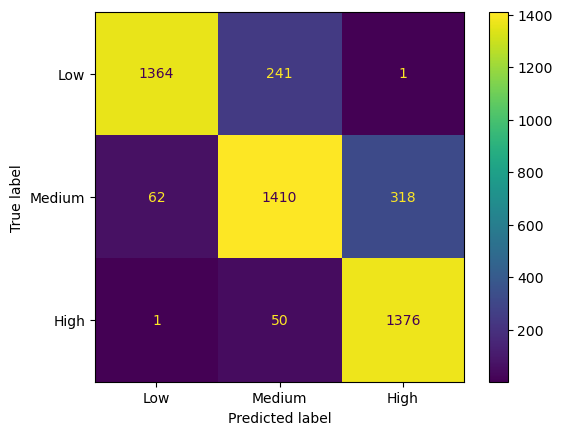

In [11]:
from data_setup import get_category_function
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

to_category, low_cut, high_cut = get_category_function(y_train)

actual_cat = to_category(y_test)
predicted_cat = to_category(y_pred)   # use best_pred for Gradient Boosting

print("Category accuracy:", accuracy_score(actual_cat, predicted_cat))

labels = ["Low", "Medium", "High"]
cm = confusion_matrix(actual_cat, predicted_cat, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot()